# Emilie

In [278]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import time



## FRA AMANDA:

In [279]:
#Tokamak magentic field
#The static magentic field
def B_tokamak(x):
    Bx = -(2*x[1]+ x[0]*x[2])/(2*(x[0]**2 + x[1]**2))
    By = (2*x[0]- x[1]*x[2])/(2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2)-1)/(2*(np.sqrt(x[0]**2 + x[1]**2)))
    return np.array([Bx, By, Bz])


#The vector potential
def A_tokamak(x):
    Ax = 0
    Ay = 1/2 *(x[0] - np.log(np.sqrt(x[0]**2 + x[1]**2) + x[0]))
    Az = -1/2 * (x[2]*np.arctan(x[1]/x[0])+ np.log(x[0]**2 + x[1]**2))
    return np.array([Ax, Ay, Az])

#The electrostatic potential
def U_tokamak(x):
    return 0

#The gradient of the electrostatic potential
def grad_U_tokamak(x):
    return 0

#Initial values
x0_tokomak = np.array([1.2, 0.0, 0.0])
v0_tokomak = np.array([0, 4.816e-4, -2.059e-3])

#2D charged particle
#The static magentic field
def B_2D(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])

#The vector potential
def A_2D(x):
    Ax = -x[1]*np.sqrt(x[0]**2 + x[1]**2)
    Ay = x[0]*np.sqrt(x[0]**2+ x[1]**2)
    Az = 0
    return 1/3 * np.array([Ax, Ay, Az])

#The electrostatic potential
def U_2D(x):
    return 1/(100*np.sqrt(x[0]**2 + x[1]**2))

#The gradient of the electrostatic potential
def grad_U_2D(x):
    Ux = x[0]/((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1]/((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100*np.array([Ux, Uy, Uz])

#Initial values  FJERNET TRANSPONERING HER
x0_2D = np.array([0.0, 1.0, 0.1])
v0_2D = np.array([0.09, 0.05, 0.20])

# Implementation of Boris method

In [280]:
def ODEs(t, y, B, U, Ugrad):
    x, v = y[:3], y[3:] # y needs to be all the parameters for solve_ivp to work
    return np.concatenate([v, np.cross(v, B(x)) - Ugrad(x)])

def boris_method(ODEs, x0, v0, h, U, U_grad, B, bool_init,N):
    """
    General Boris method
    """
    # If the initial condition is the actual initial condition (want one step back)
    v_back = v0

    if bool_init: #if we are given (x0,v0) instead
        t_0 = 0
        t_back = t_0-(h/2)
        t_span = [t_0, t_back]

        initial_condition = np.concatenate((x0,v0))

        sol = solve_ivp(ODEs, t_span, initial_condition, args=(B, U, U_grad), first_step = (h/2), rtol=1e-10, atol=1e-12)
        v_back = sol.y[3:,-1] #???????????
    
    # The actual Boris method

    x_n = x0
    v_n_half = v_back
    
    x_array = np.zeros((3,N)) 
    v_array = np.zeros((3,N))

    start = time.perf_counter() # START MEASURING TIME

    for i in range(0,N):
        t = h/2*B(x_n)
        s = 2*t / (1 + np.dot(t, t))

        v_minus = v_n_half - (h/2)*U_grad(x_n)
        v_mark = v_minus + np.cross(v_minus, t)
        
        v_pluss = v_minus + np.cross(v_mark,s)

        v_n_pluss_half = v_pluss - (h/2)*U_grad(x_n)
        x_n_pluss_one = x_n + h*v_n_pluss_half

        # Update values:
        x_n = x_n_pluss_one
        v_n_half = v_n_pluss_half

        #put values into lists for plotting
        x_array[:,i] = x_n
        v_array[:,i] = v_n_half

    end = time.perf_counter() # STOP MEASURING TIME

    time_spent = end - start
        
    return x_array, v_array, time_spent

In [281]:
N = int(10**5/ 0.1)

x_array_boris, v_array_boris, _ = boris_method(ODEs, x0_2D, v0_2D, 0.1,U_2D, grad_U_2D, B_2D, True, N)
;

''

In [282]:
x_array_boris_toko, v_array_boris_toko, _ = boris_method(ODEs, x0_tokomak, v0_tokomak, 0.1,U_tokamak, grad_U_tokamak, B_tokamak, True, N)

## Plotting trajectories over time

Text(0, 0.5, 'y')

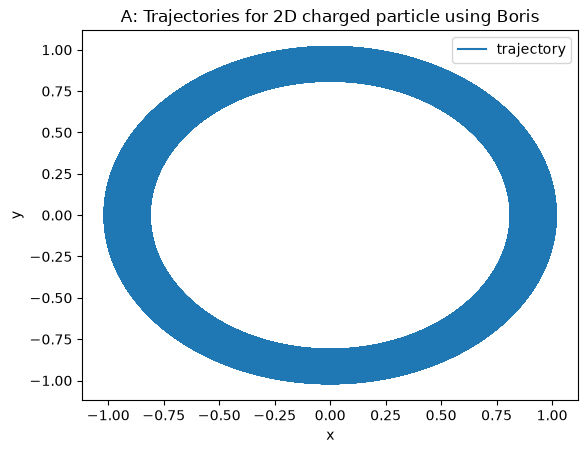

In [283]:
plt.title("A: Trajectories for 2D charged particle using Boris")
plt.plot(x_array_boris[0], x_array_boris[1], label = "trajectory")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")

Text(0, 0.5, 'y')

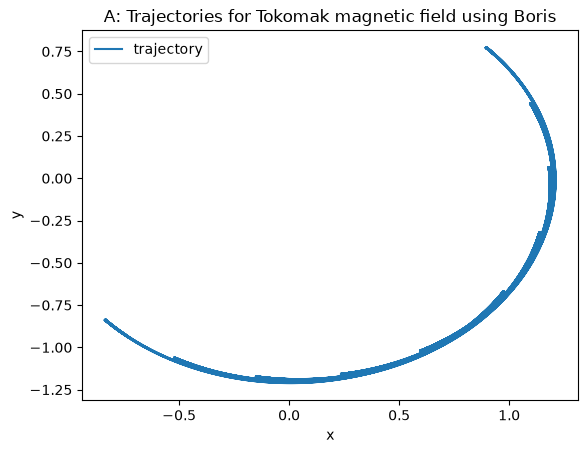

In [284]:
plt.title("A: Trajectories for Tokomak magnetic field using Boris")
plt.plot(x_array_boris_toko[0], x_array_boris_toko[1], label = "trajectory")
plt.legend()
plt.xlabel("x")
plt.ylabel("y")


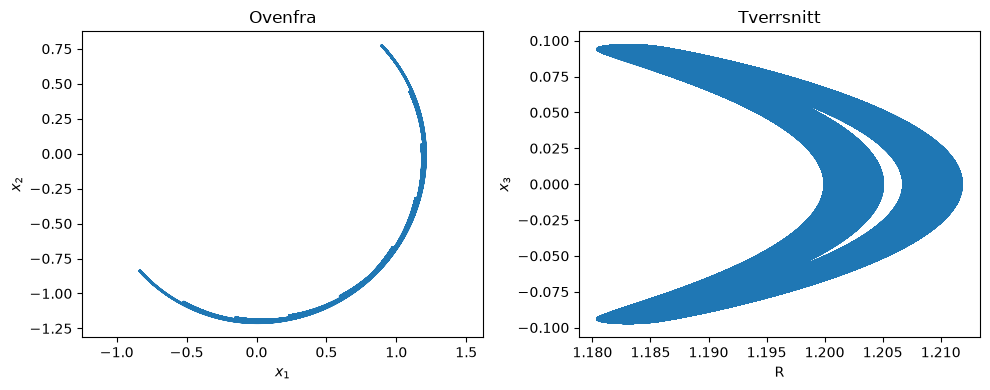

In [285]:
R_boris = np.sqrt(x_array_boris_toko[0]**2 + x_array_boris_toko[1]**2)
z = x_array_boris_toko[2]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.plot(x_array_boris_toko[0], x_array_boris_toko[1])
ax1.set_xlabel("$x_1$")
ax1.set_ylabel("$x_2$")
ax1.set_title("Ovenfra")
ax1.axis("equal")

ax2.plot(R_boris, z)
ax2.set_xlabel("R")
ax2.set_ylabel("$x_3$")
ax2.set_title("Tverrsnitt")

plt.tight_layout()
plt.show()

In [286]:
T = 10**5
h = 0.1
t_span = (0, T)
t_eval = np.arange(N) * h
print(len(t_eval))

initial_condition_2D = np.concatenate((x0_2D,v0_2D))
initial_condition_toko = np.concatenate((x0_tokomak,v0_tokomak))

sol = solve_ivp(ODEs, t_span, initial_condition_2D,
                args=(B_2D, U_2D, grad_U_2D),
                method="DOP853", rtol=1e-10, atol=1e-12, t_eval=t_eval)



1000000


In [287]:
sol_toko = solve_ivp(ODEs, t_span, initial_condition_toko,
                args=(B_tokamak, U_tokamak, grad_U_tokamak),
                method="DOP853", rtol=1e-10, atol=1e-12, t_eval=t_eval)

Text(0.5, 1.0, 'Error of Boris method for 2D')

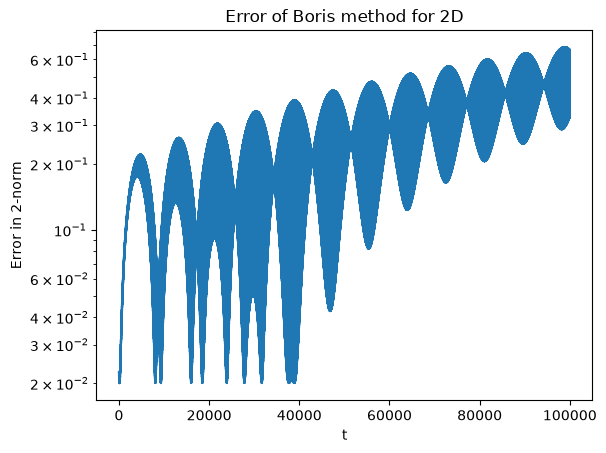

In [288]:
x1,x2,x3 = sol.y[0:3]

error_boris_2d= np.linalg.norm(x_array_boris - sol.y[0:3], axis = 0, ord = 2)

plt.plot(t_eval, error_boris_2d)
plt.xlabel("t")
plt.ylabel("Error in 2-norm")
plt.yscale("log")
plt.title("Error of Boris method for 2D")

Text(0.5, 1.0, 'Error of Boris method for Tokomak magnetic field')

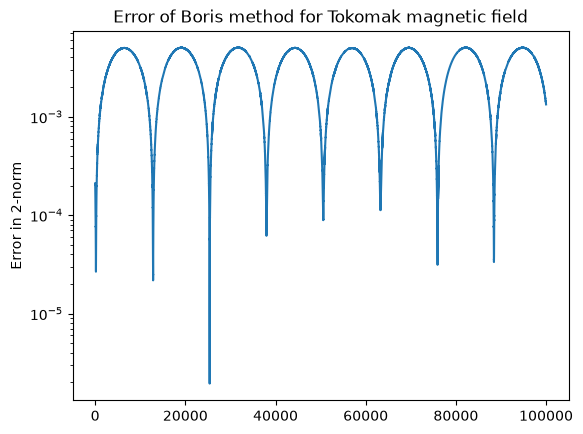

In [289]:
error_toko_boris = np.linalg.norm(x_array_boris_toko - sol_toko.y[0:3], axis = 0, ord = 2)
plt.plot(t_eval, error_toko_boris)
plt.ylabel("Error in 2-norm")
plt.yscale("log")
plt.title("Error of Boris method for Tokomak magnetic field")

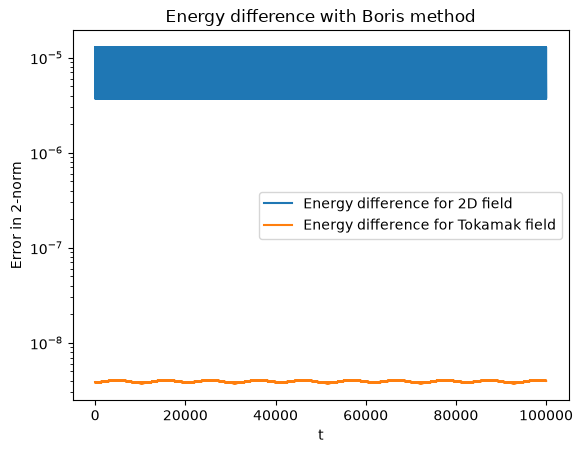

In [290]:
def energy_change_boris(x,v, initial_values, U):

    v_at_integers = 0.5* (v[:,:-1] + v[:, 1:])


    energy_at_zero = 0.5*np.linalg.norm(initial_values[3:], ord = 2)**2 + U(initial_values[0:3])

    x_array = x[:, :-1]

    energy_at_x_v =  0.5*np.linalg.norm(v_at_integers, ord = 2, axis = 0)**2 + U(x_array)

    diff = np.abs(energy_at_x_v - energy_at_zero)

    return diff

energy_change_boris_2D = energy_change_boris(x_array_boris, v_array_boris, initial_condition_2D, U_2D)
energy_change_boris_toko = energy_change_boris(x_array_boris_toko, v_array_boris_toko, initial_condition_toko, U_tokamak)

t_eval_boris = t_eval[:-1]

plt.plot(t_eval_boris, energy_change_boris_2D, label = "Energy difference for 2D field")
plt.plot(t_eval_boris, energy_change_boris_toko, label = "Energy difference for Tokamak field")
plt.title("Energy difference with Boris method")
plt.ylabel("Error in 2-norm")
plt.xlabel("t")
plt.legend()
plt.yscale("log")

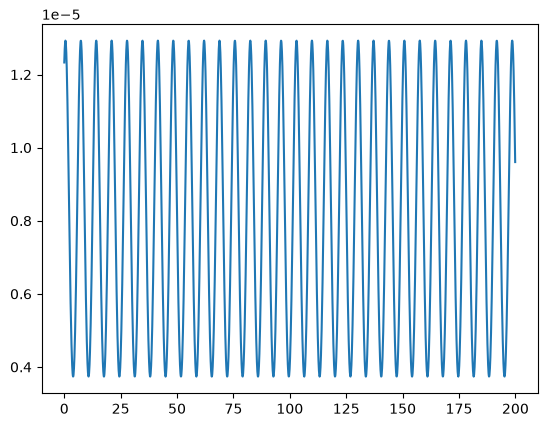

In [291]:
plt.plot(t_eval[:2000], energy_change_boris_2D[:2000])

In [292]:
def error_boris_decrease():
    h = 0.1
    h_i = [h, h/2, h/4]
    T = 10**3
    errors_2d = []
    errors_toko = []
    time_list_2d = []
    time_list_toka = []

    for i in range(3):
        N_i = int(T/h_i[i])+1

        t_span = (0,10**3)
        t_eval = np.arange(N_i) * h_i[i]

        x_boris_2D, y_boris_2D, time_2d = boris_method(ODEs,x0_2D,v0_2D,h_i[i],U_2D, grad_U_2D,B_2D, True, N_i)
        

        sol_2D = solve_ivp(ODEs, t_span, initial_condition_2D,
                args=(B_2D, U_2D, grad_U_2D),
                method="DOP853", rtol=1e-10, atol=1e-12, t_eval=t_eval)

        
        x_boris_toko, y_boris_toka, time_toka = boris_method(ODEs,x0_tokomak,v0_tokomak,h_i[i],U_tokamak, grad_U_tokamak,B_tokamak, True, N_i)

        time_list_2d.append(time_2d)
        time_list_toka.append(time_toka)


        sol_toko = solve_ivp(ODEs, t_span, initial_condition_toko,
                args=(B_tokamak, U_tokamak, grad_U_tokamak),
                method="DOP853", rtol=1e-10, atol=1e-12, t_eval=t_eval)

        # Compare last step global error

        x_last_2D = x_boris_2D[:,-1]
        x_last_2D_ref = sol_2D.y[:3,-1]

        x_last_toko = x_boris_toko[:,-1]
        x_last_toko_ref = sol_toko.y[:3,-1]

        norm_2D = np.linalg.norm(x_last_2D - x_last_2D_ref, ord = 2)
        norm_toko = np.linalg.norm(x_last_toko - x_last_toko_ref, ord = 2)

        errors_2d.append(norm_2D)
        errors_toko.append(norm_toko)

    return errors_2d, errors_toko, time_list_2d, time_list_toka


In [293]:
error_2D, error_toka, time_2d, time_toka = error_boris_decrease()

[]

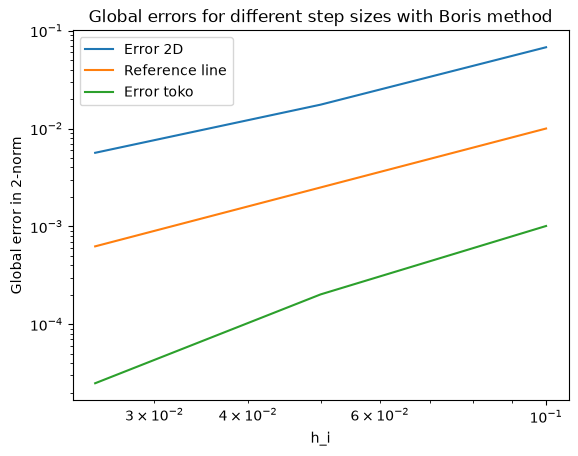

In [294]:
plt.title("Global errors for different step sizes with Boris method")
h_i = [h, h/2, h/4]
h_p = [i**2 for i in h_i]


plt.plot(h_i, error_2D, label = "Error 2D")
plt.plot(h_i, h_p, label = "Reference line")
plt.plot(h_i, error_toka, label = "Error toko")


plt.xlabel("h_i")
plt.ylabel("Global error in 2-norm")
plt.legend()
plt.loglog()

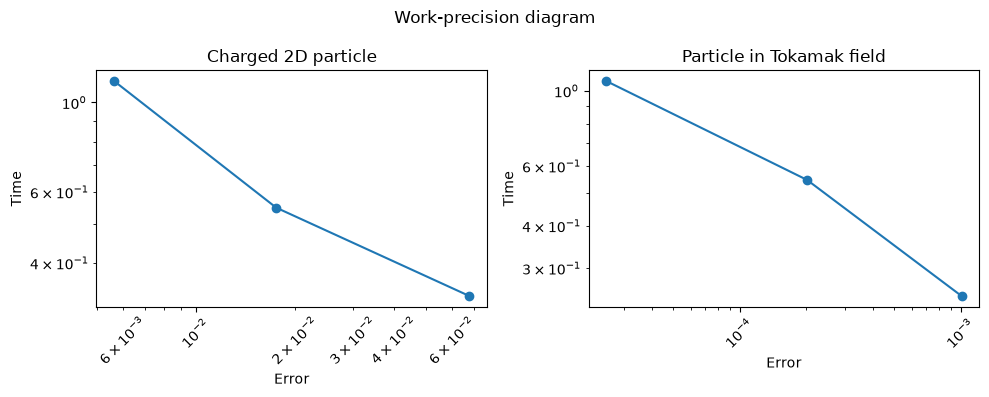

In [299]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.loglog(error_2D, time_2d, "o-")
ax1.set_title("Charged 2D particle")
ax1.set_xlabel("Error")
ax1.set_ylabel("Time")
ax1.tick_params(axis='x',which = "both", labelrotation=45)

ax2.loglog(error_toka, time_toka, "o-")
ax2.set_title("Particle in Tokamak field")
ax2.set_xlabel("Error")
ax2.set_ylabel("Time")
ax2.tick_params(axis='x',which = "both", labelrotation=45)

fig.suptitle("Work-precision diagram")
plt.tight_layout()
plt.show()

# Amanda

# Project 2: Numerical Integration For Charged Particles

### Classical Runge-Kutta 4 on the extended system

In [132]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import scipy 

import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
from functools import partial
import time as pytime
import time


#### Model problems 

In [133]:
# 2D charged particle

# The static magnetic field
def B_2D(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])

def B_2D_np(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])


# The vector potential
def A_2D(x):
    Ax = -x[1] * np.sqrt(x[0]**2 + x[1]**2)
    Ay = x[0] * np.sqrt(x[0]**2 + x[1]**2)
    Az = 0
    return 1/3 * np.array([Ax, Ay, Az])


# The electrostatic potential
def U_2D(x):
    return 1 / (100 * np.sqrt(x[0]**2 + x[1]**2))


# The gradient of the electrostatic potential
def grad_U_2D(x):
    Ux = x[0] / ((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1] / ((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100 * np.array([Ux, Uy, Uz])


def grad_U_2D_np(x):
    Ux = x[0] / ((x[0]**2 + x[1]**2)**(3/2))
    Uy = x[1] / ((x[0]**2 + x[1]**2)**(3/2))
    Uz = 0
    return -1/100 * np.array([Ux, Uy, Uz])


# Initial values
x0_2D = np.array([0.0, 1.0, 0.1], dtype=np.float64)
v0_2D = np.array([0.09, 0.05, 0.20], dtype=np.float64)

In [134]:
# Tokamak magnetic field

# The static magnetic field
def B_tokamak(x):
    Bx = -(2*x[1] + x[0]*x[2]) / (2*(x[0]**2 + x[1]**2))
    By = (2*x[0] - x[1]*x[2]) / (2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2) - 1) / (2*np.sqrt(x[0]**2 + x[1]**2))
    return np.array([Bx, By, Bz])


def B_tokamak_np(x):
    Bx = -(2*x[1] + x[0]*x[2]) / (2*(x[0]**2 + x[1]**2))
    By = (2*x[0] - x[1]*x[2]) / (2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2) - 1) / (2*np.sqrt(x[0]**2 + x[1]**2))
    return np.array([Bx, By, Bz])


# The vector potential
def A_tokamak(x):
    Ax = 0
    Ay = 1/2 * (x[0] - np.log(np.sqrt(x[0]**2 + x[1]**2) + x[0]))
    Az = -1/2 * (x[2]*np.arctan(x[1]/x[0]) + np.log(x[0]**2 + x[1]**2))
    return np.array([Ax, Ay, Az])


# The electrostatic potential
def U_tokamak(x):
    return 0


# The gradient of the electrostatic potential
def grad_U_tokamak(x):
    return 0


# Initial values
x0_tokamak = np.array([1.2, 0.0, 0.0], dtype=np.float64)
v0_tokamak = np.array([0, 4.816*1e-4, -2.059*1e-3], dtype=np.float64)

In [136]:
#defining the numerical approximation of the derivative
#adding B and grad U as parameters so that I can reuse the functions for both models

def ODEs(t, y, B, grad_U):
    x = y[:3]
    v = y[3:]

    dxdt = v
    dvdt = np.cross(v, B(x)) - grad_U(x)
    return np.concatenate((dxdt, dvdt))


#Defining the Runge Kutta 4 method

def RK4(y_n, h, B, grad_U):
    k_1 = h * ODEs(0, y_n, B, grad_U)
    k_2 = h * ODEs(0, y_n + 0.5*k_1, B, grad_U)
    k_3 = h * ODEs(0, y_n + 0.5*k_2, B, grad_U)
    k_4 = h * ODEs(0, y_n + k_3, B, grad_U)

    return y_n + (k_1 + 2*k_2 + 2*k_3 + k_4)/6




## A - Plotting trajectories and error over long time

In [138]:
# Parameters
T = 1e5
h = 0.1
n_steps = int(T/h)
time = np.linspace(0, T, n_steps + 1)

# Preallocating arrays
y_arr_2D = np.zeros((n_steps + 1, 6))

# Initial condition: position + velocity
y_arr_2D[0] = np.concatenate((np.asarray(x0_2D), np.asarray(v0_2D)))

y_n = np.concatenate((x0_2D, v0_2D))

for i in tqdm(range(n_steps)):
    y_n = RK4(y_n, h, B_2D, grad_U_2D)
    y_arr_2D[i+1] = np.asarray(y_n)

# Extracting position and velocity
x_arr_2D = y_arr_2D[:, :3]
v_arr_2D = y_arr_2D[:, 3:]
    
       

100%|██████████| 1000000/1000000 [01:06<00:00, 15051.86it/s]


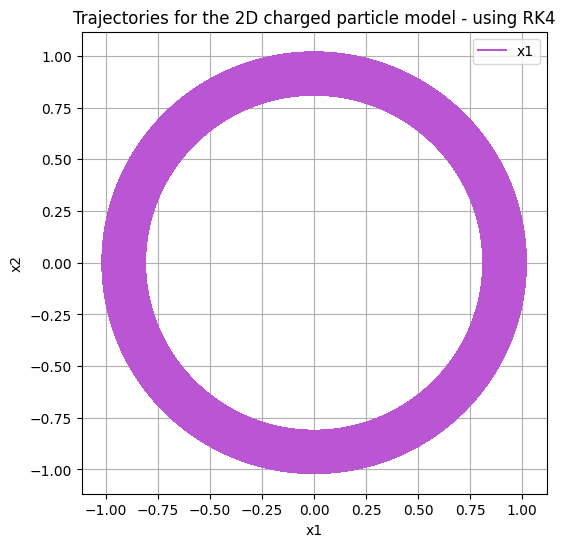

In [139]:
#Plotting the trajectories of the two first coordinates of the solutions
plt.figure(figsize=(6,6))
plt.plot(x_arr_2D[:, 0],x_arr_2D[:, 1], color = 'mediumorchid', label = 'x1')
plt.xlabel('x1')
plt.ylabel('x2')
plt.title('Trajectories for the 2D charged particle model - using RK4')
plt.legend()
plt.grid(True)
plt.show()


In [140]:
# Parameters
T = 1e5
h = 0.1
n_steps = int(T/h)
time = np.linspace(0, T, n_steps + 1)

# Preallocating array
y_arr_tokamak = np.zeros((n_steps + 1, 6))

# Initial condition: position + velocity
y_arr_tokamak[0] = np.concatenate((
    np.asarray(x0_tokamak), np.asarray(v0_tokamak)))

y_n = np.concatenate((x0_tokamak, v0_tokamak))

for i in tqdm(range(n_steps)):
    y_n = RK4(y_n, h, B_tokamak, grad_U_tokamak)
    y_arr_tokamak[i+1] = np.asarray(y_n)

# Extracting position and velocity
x_arr_tokamak = y_arr_tokamak[:, :3]
v_arr_tokamak = y_arr_tokamak[:, 3:]

100%|██████████| 1000000/1000000 [01:11<00:00, 13933.26it/s]


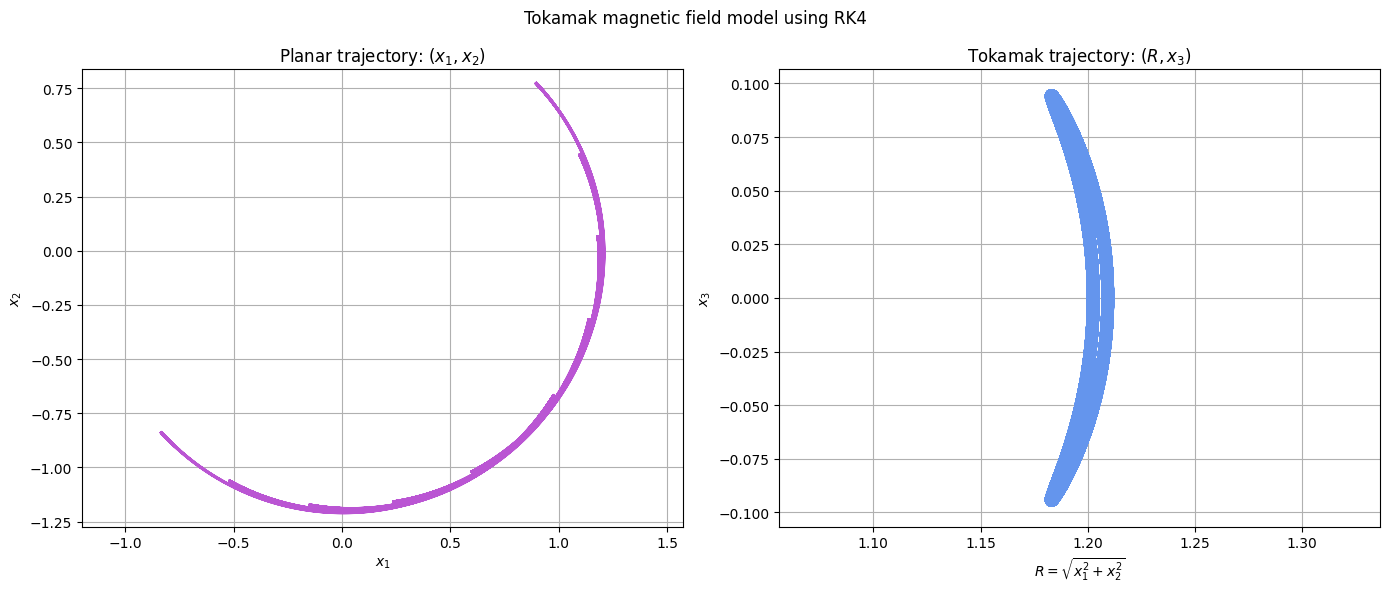

In [141]:
#Plotting the trajectories of the two first coordinates of the solutions
# Cylindrical radial coordinate
R = np.sqrt(x_arr_tokamak[:, 0]**2 + x_arr_tokamak[:, 1]**2)
x3 = x_arr_tokamak[:, 2]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Trajectory in the x1-x2 plane
axes[0].plot(x_arr_tokamak[:, 0],x_arr_tokamak[:, 1],color="mediumorchid")
axes[0].set_xlabel(r"$x_1$")
axes[0].set_ylabel(r"$x_2$")
axes[0].set_title(r"Planar trajectory: $(x_1,x_2)$")
axes[0].axis("equal")
axes[0].grid(True)

# Trajectory in the R-x3 plane
axes[1].plot(R,x3, color="cornflowerblue")
axes[1].set_xlabel(r"$R=\sqrt{x_1^2+x_2^2}$")
axes[1].set_ylabel(r"$x_3$")
axes[1].set_title(r"Tokamak trajectory: $(R,x_3)$")
axes[1].axis("equal")
axes[1].grid(True)

fig.suptitle("Tokamak magnetic field model using RK4")
plt.tight_layout()
plt.show()


---------------------------------------------------------------------------

In [142]:
#Testing for a shorter time interval because 
t_span_test = (0, 100)
t_eval_test = np.linspace(0, 100, 1001)

initial_condition_2D = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))


sol_test = scipy.integrate.solve_ivp(
    ODEs,
    t_span_test,
    initial_condition_2D,
    args=(B_2D, grad_U_2D),
    method='DOP853',
    rtol=1e-10,
    atol=1e-12,
    t_eval=t_eval_test
)

print("Success:", sol_test.success)
print("Function evaluations:", sol_test.nfev)
print("Message:", sol_test.message)

Success: True
Function evaluations: 5159
Message: The solver successfully reached the end of the integration interval.


In [143]:
#Plotting the error over time for the RK4 method
t_span = (0, T)
t_eval = np.arange(0, T+h, h)

initial_condition_2D = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))

sol_2D = scipy.integrate.solve_ivp(ODEs, t_span, initial_condition_2D, 
                                   args=(B_2D, grad_U_2D),
                                   method = 'DOP853',
                                   rtol = 1e-10,
                                   atol=1e-12,
                                   t_eval = t_eval)

sol_tokamak= scipy.integrate.solve_ivp(ODEs, t_span, initial_condition_tokamak, 
                                   args=(B_tokamak, grad_U_tokamak),
                                   method = 'DOP853',
                                   rtol = 1e-10,
                                   atol=1e-12,
                                   t_eval = t_eval)


print(sol_2D.success, sol_2D.message)
print(sol_tokamak.success, sol_tokamak.message)




True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.


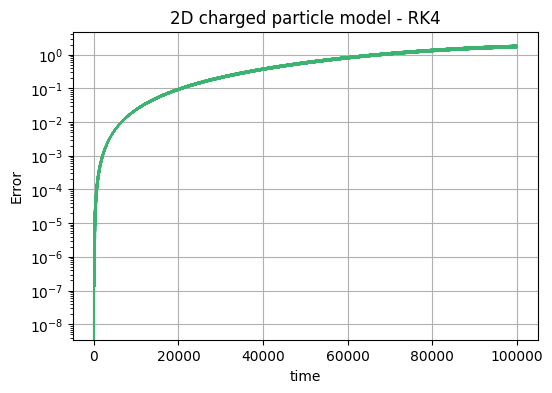

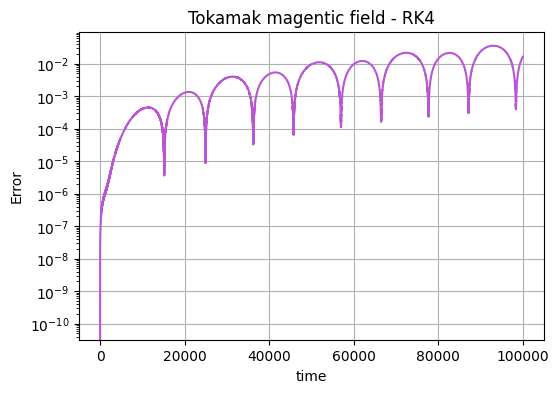

In [144]:
#Plotting the error over time for both 2D paticle model
#Transposing to switch the rows and columns to make the shapes match


error_2D = np.linalg.norm(x_arr_2D - sol_2D.y[:3, :].T, axis = 1)


plt.figure(figsize=(6,4))
plt.semilogy(t_eval, error_2D, color= 'mediumseagreen')
plt.xlabel('time')
plt.ylabel('Error')
plt.title('2D charged particle model - RK4')
plt.grid(True)
plt.show()

#Plotting the error over time for both Tokamak magnetic field
#Transposing to switch the rows and columns to make the shapes match
error_tokamak = np.linalg.norm(x_arr_tokamak - sol_tokamak.y[:3, :].T, axis = 1)


plt.figure(figsize=(6,4))
plt.semilogy(t_eval, error_tokamak, color= 'mediumorchid')
plt.xlabel('time')
plt.ylabel('Error')
plt.title('Tokamak magentic field - RK4')
plt.grid(True)
plt.show()


---------------------------------------------------------------

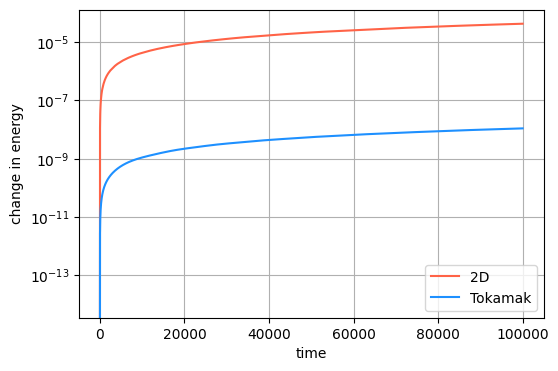

In [145]:
#Plotting the change in energy againt time 
#Defining the energyfunction
def energy(y, U):
    x = y[:, :3]
    v = y[:, 3:]

    return 0.5*np.linalg.norm(v, axis=1)**2 +np.array([float(U(x_i)) for x_i in x]) 

initial_condition_2D = np.concatenate((x0_2D,v0_2D))
initial_condition_tokamak = np.concatenate((x0_tokamak,v0_tokamak))

E0_2D = energy(initial_condition_2D.reshape(1, 6), U_2D)[0]
E0_tokamak = energy(initial_condition_tokamak.reshape(1, 6), U_tokamak)[0]

#Calculating the change in energy
e_n_2D = np.abs(energy(y_arr_2D, U_2D) - E0_2D)
e_n_tokamak = np.abs(energy(y_arr_tokamak, U_tokamak) - E0_tokamak)

#Plot
plt.figure(figsize=(6,4))
plt.semilogy(t_eval, e_n_2D, color= 'tomato', label = '2D')
plt.semilogy(t_eval, e_n_tokamak, color = 'dodgerblue', label = 'Tokamak')
plt.xlabel('time')
plt.ylabel('change in energy')
plt.legend()
plt.grid(True)
plt.show()

## Task B) Order verification and work precision diagrams

In [146]:

#Paramaters
h = 0.1
h_i = np.array([h, h/2 , h/4])


T = 1e4
N_i = (T/h_i).astype(int)

for i in range(3):
    print(h_i[i], N_i[i]*h_i[i])

#2D
# Preallocating arrays
y_arr_2D_i = [
    np.zeros((N_i[0] + 1, 6)),
    np.zeros((N_i[1] + 1, 6)), 
    np.zeros((N_i[2] + 1, 6))
    ]

# Initial condition: position + velocity
y0 = np.concatenate((np.asarray(x0_2D), np.asarray(v0_2D)))
                          
for i in range(3):
    y_arr_2D_i[i][0] = y0


tau_2D_i = []

for i in range(3):
    #Resetting y_n before each simulation
    y_n = np.concatenate((x0_2D, v0_2D))

    start = pytime.perf_counter()
    for j in tqdm(range(N_i[i])):
        y_n = RK4(y_n, h_i[i], B_2D, grad_U_2D)
        y_arr_2D_i[i][j+1] = np.asarray(y_n)

    end = pytime.perf_counter()
    tau_2D_i.append(end-start)
    

# Extracting position and velocity
x_arr_2D_i = [y[:, :3] for y in y_arr_2D_i]
v_arr_2D_i =[y[:, 3:] for y in y_arr_2D_i]



0.1 10000.0
0.05 10000.0
0.025 10000.0


100%|██████████| 400000/400000 [00:26<00:00, 14919.13it/s]


In [147]:
#Tokamak
# Preallocating array
y_arr_tokamak_i = [
    np.zeros((N_i[0] + 1, 6)),
    np.zeros((N_i[1] + 1, 6)), 
    np.zeros((N_i[2] + 1, 6))
    ]


# Initial condition: position + velocity
y0 = np.concatenate((np.asarray(x0_tokamak), np.asarray(v0_tokamak)))

for i in range(3):
    y_arr_tokamak_i[i][0] = y0

tau_tokamak_i = []

for i in range(3):
    #Resetting y_n before each simulation
    y_n = np.concatenate((x0_tokamak, v0_tokamak))

    start = pytime.perf_counter()

    for j in tqdm(range(N_i[i])):
        y_n = RK4(y_n, h_i[i], B_tokamak, grad_U_tokamak)
        y_arr_tokamak_i[i][j+1] = np.asarray(y_n)
    end = pytime.perf_counter()
    tau_tokamak_i.append(end-start)


# Extracting position and velocity
x_arr_tokamak_i = [y[:, :3] for y in y_arr_tokamak_i]
v_arr_tokamak_i =[y[:, 3:] for y in y_arr_tokamak_i]

print(tau_tokamak_i)

100%|██████████| 400000/400000 [00:28<00:00, 13830.07it/s]

[7.070081084006233, 14.278191249992233, 28.924469916004455]


In [148]:
#Solve_ivp for all three step sizes
sol_2D_i = []
sol_tokamak_i = []

for i in range(3):
    t_eval_i = np.arange(0, T + h_i[i]/2, h_i[i])
    sol_2D_i.append(
        scipy.integrate.solve_ivp(ODEs, (0, T), initial_condition_2D, 
                args=(B_2D, grad_U_2D),
                method = 'DOP853',
                rtol = 1e-10,
                atol=1e-12,
                t_eval = t_eval_i)

    )
    
    sol_tokamak_i.append(
        scipy.integrate.solve_ivp(ODEs, (0, T), initial_condition_tokamak, 
                args=(B_tokamak, grad_U_tokamak),
                method = 'DOP853',
                rtol = 1e-10,
                atol=1e-12,
                t_eval = t_eval_i)

    )
    

for i in range(3):
    print(f"h = {h_i[i]}:")
    print(sol_2D_i[i].success, sol_2D_i[i].message)
    print(sol_tokamak_i[i].success, sol_tokamak_i[i].message)

h = 0.1:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.
h = 0.05:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.
h = 0.025:
True The solver successfully reached the end of the integration interval.
True The solver successfully reached the end of the integration interval.


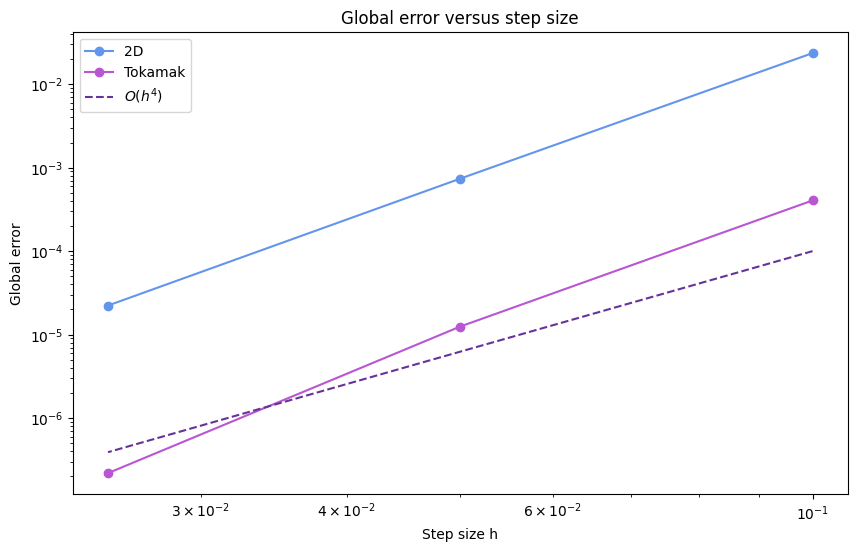

In [149]:
#Comuting the error in the last step
error_2D_i = []

for i in range(3):
    error_2D_i.append(np.linalg.norm(x_arr_2D_i[i][-1, :] - sol_2D_i[i].y[:3, -1]))


error_tokamak_i = []

for i in range(3):
    error_tokamak_i.append(np.linalg.norm(x_arr_tokamak_i[i][-1, :] - sol_tokamak_i[i].y[:3, -1]))


#Plotting
plt.figure(figsize=(10,6))

plt.loglog(h_i, error_2D_i, 'o-', label='2D', color= 'cornflowerblue')
plt.loglog(h_i, error_tokamak_i, 'o-', label='Tokamak', color= 'mediumorchid')

plt.loglog(h_i, h_i**4, '--', label=r'$O(h^4)$', color= 'rebeccapurple')

plt.xlabel('Step size h')
plt.ylabel('Global error')
plt.title('Global error versus step size')
plt.legend()

plt.show()


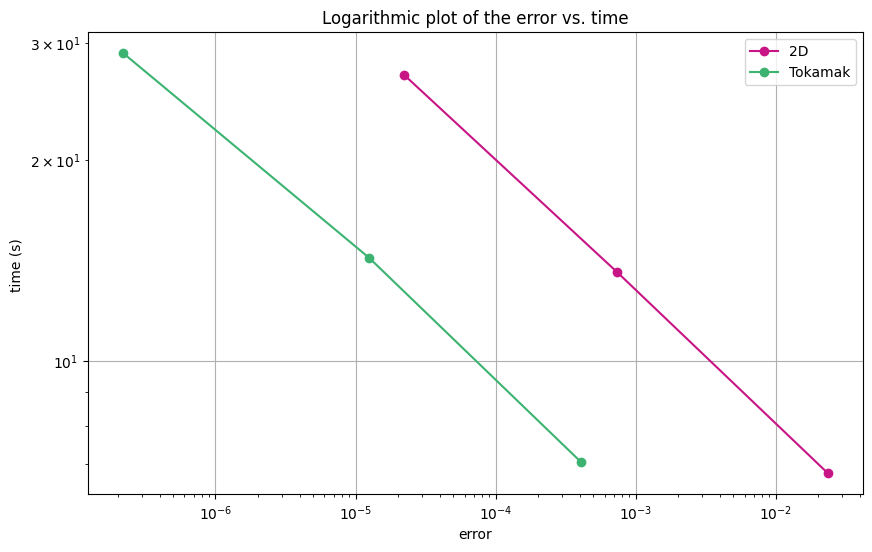

In [150]:
#plotting the error vs. time with the RK4 method

plt.figure(figsize=(10, 6))
plt.loglog(error_2D_i, tau_2D_i, 'o-' , color = 'mediumvioletred', label = '2D')
plt.loglog(error_tokamak_i, tau_tokamak_i, 'o-', color = 'mediumseagreen', label = 'Tokamak')
plt.xlabel('error')
plt.ylabel('time (s) ')
plt.title('Logarithmic plot of the error vs. time')
plt.legend()
plt.grid(True)
plt.show()

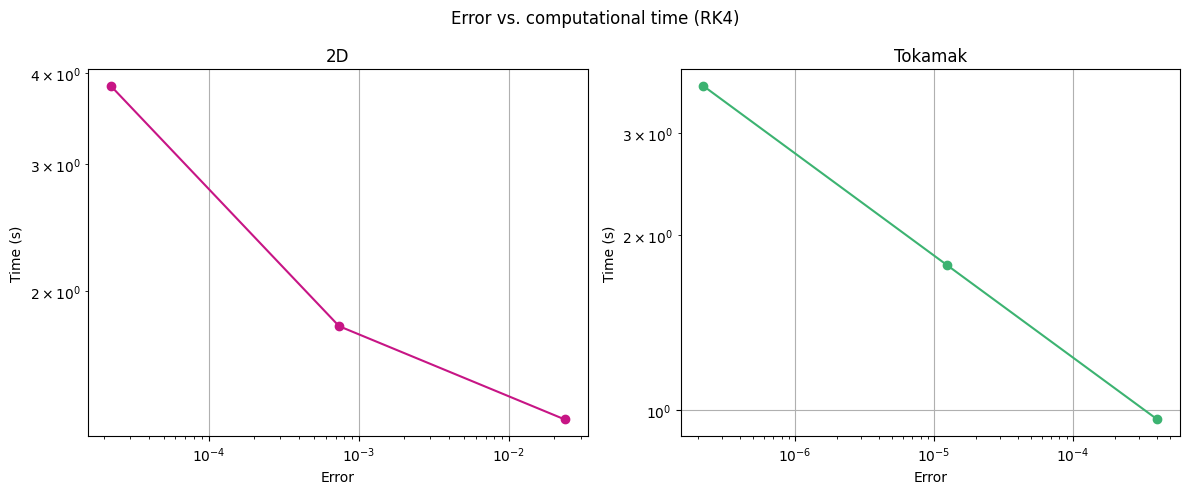

In [131]:
#The same only this time in two subplots

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# 2D
ax[0].loglog(error_2D_i, tau_2D_i, 'o-', color='mediumvioletred')
ax[0].set_xlabel('Error')
ax[0].set_ylabel('Time (s)')
ax[0].set_title('2D')
ax[0].grid(True)

# Tokamak
ax[1].loglog(error_tokamak_i, tau_tokamak_i, 'o-', color='mediumseagreen')
ax[1].set_xlabel('Error')
ax[1].set_ylabel('Time (s)')
ax[1].set_title('Tokamak')
ax[1].grid(True)

fig.suptitle('Error vs. computational time (RK4)')
plt.tight_layout()
plt.show()

# Seline

In [300]:
from scipy.integrate import solve_ivp
#from scipy.differentiate import jacobian
from scipy.optimize import approx_fprime
import numpy as np
import matplotlib.pyplot as plt
from time import perf_counter

Implementation of Fourth-order symmetric multistep method:

In [301]:
def starting_values(y0, t_min, t_max, U_grad, B):
    t_vals = np.linspace(t_min, t_max, 8)
    solution = solve_ivp(ODE1,(t_min,t_max) , np.concatenate(y0), args=(B, U_grad), t_eval = t_vals, rtol=1e-12, atol=1e-14, method="DOP853") #y0 must be [x0, v0]
    return solution.y, solution.t

def v(x,j, h):
    return delta(x, j)/h

def delta(y, j):#five point central difference
    return 1/12*(y[:,j-2] - 8*y[:,j-1] + 8*y[:,j+1] - y[:,j+2])

def deltaA(A, x, j):#five point central difference
    return 1/12*(A(x[:,j-2]) - 8*A(x[:,j-1]) + 8*A(x[:,j+1]) - A(x[:,j+2]))

def F_j(A, v, U_grad, j, x, h):
    A_jac = np.transpose(approx_fprime(x[:,j], A))
    #A_jac = np.transpose(jacobian(A, x[:,j]))

    A_delta = deltaA(A,x, j)/h
    return A_jac@v(x,j,h) - A_delta - U_grad(x[:,j])

def FOSMM_step(alpha, x , n, h, A, v, U_grad, beta): #find x_(n+4)
    sum = 0
    for j in range(-4, 4):
        sum += alpha[4+j]*x[:,n+j]
    x[:,n+4] = 1/alpha[-1]*(h**2*(beta[1]*F_j(A, v, U_grad,  n-1, x, h) + beta[0]*F_j(A, v, U_grad, n, x, h) + beta[1]*F_j(A, v, U_grad, n+1, x, h))  - sum)
    #v_arr[:,n+4] = v(x, n+4, h)

def t_j(t0, j, h):
    return t0 + j*h

def ODE1(t, y, B, U_grad):
    x = y[:3]
    v = y[3:]

    x_dot = v
    v_dot = np.cross(v,B(x))-U_grad(x)
    return np.concatenate([x_dot, v_dot])



def FOSMM(alpha, h, A, U_grad,B, beta, T_max, y0): #y0 = [x0, v0]
    N = int(T_max/h) + 1 #number of steps
    start_vals = starting_values(y0, 0, 7*h, U_grad, B) #0 til 7 riktig??
    x_start = start_vals[0][:3, :] #from t= 0 to 7
    v_start = start_vals[0][3:, :]

    x_arr = np.zeros((3,N+2))
    v_arr = np.zeros((3,N))

    x_arr[:, :8] = x_start    
    v_arr[:, :8] = v_start
    #todo: må B, U være evaluerte funkjsoner eller kaqn de vøre dunksjoner?
    #n = 8
    start = perf_counter()
    for n in range(8, N+2): #evaluate two extra steps in order to find the last value of v

        if(n%10==0):
            print(f"{n/N*100}%")
        FOSMM_step(alpha, x_arr, n-4, h, A, v, U_grad, beta)
        v_arr[:,n-2] = v(x_arr, n-2, h)

        #t += h #må t lagres?
        #n+=1
    stop = perf_counter()
    return x_arr[:, :N], v_arr, stop - start


h = 0.1
a = [-0.7, 0.1, 0.9]
beta = [1/3*(20*a[0]*a[1]*a[2]-4*(a[0]*a[1]+a[0]*a[2] + a[1]*a[2])-28*(a[0] + a[1] + a[2])-52), 1/3*(2*a[0]*a[1]*a[2] + 14*(a[0]*a[1] + a[0]*a[2] + a[1]*a[2]) + 26*(a[0]+a[1]+a[2]) + 38)]
alpha = [1, -7/5, 9/25, 22/125, -34/125, 22/125, 9/25, -7/5, 1]
T_max = 1e5

Task A on model 3.1 with Fourth-order symmetric multistep method:

In [302]:
x01 = np.array([0.0, 1.0, 0.1])
v01 = np.array([0.09, 0.05, 0.20])
y01 = np.array([x01, v01])

# in the following, x is one 3 element vector in x matrix

def B1(x):
    return np.array([0, 0, np.sqrt(x[0]**2 + x[1]**2)])

def A1(x):
    return 1/3*np.array([-x[1]*np.sqrt(x[0]**2 + x[1]**2), x[0]*np.sqrt(x[0]**2 + x[1]**2), 0])

#x = np.array([[1,2,3,4,5,6,7,8,9], [1,2,3,4,5,6,7,8,9], [1,2,3,4,5,6,7,8,9]])
#print(A1(np.array(x[:,1])))

def U1(x):
    return 1/(100*np.sqrt(x[0]**2 + x[1]**2))

def U_grad1(x):
    return -1/100*np.array([x[0]/(x[0]**2 + x[1]**2)**(3/2), x[1]/(x[0]**2 + x[1]**2)**(3/2), 0])

x1, v1, _ = FOSMM(alpha, h, A1, U_grad1, B1, beta, T_max, y01)

0.000999999000001%
0.001999998000002%
0.002999997000003%
0.003999996000004%
0.0049999950000050005%
0.005999994000006%
0.006999993000007%
0.007999992000008%
0.008999991000009%
0.009999990000010001%
0.010999989000011%
0.011999988000012%
0.012999987000013%
0.013999986000014%
0.014999985000014999%
0.015999984000016%
0.016999983000017%
0.017999982000018%
0.018999981000018998%
0.019999980000020002%
0.020999979000021%
0.021999978000022%
0.022999977000023%
0.023999976000024%
0.024999975000024998%
0.025999974000026%
0.026999973000027003%
0.027999972000028%
0.028999971000029%
0.029999970000029998%
0.030999969000031%
0.031999968000032%
0.032999967000033%
0.033999966000034%
0.034999965000035%
0.035999964000036%
0.036999963000037%
0.037999962000037996%
0.038999961000039%
0.039999960000040004%
0.040999959000041%
0.041999958000042%
0.042999957000043%
0.043999956000044%
0.044999955000045%
0.045999954000046%
0.046999953000047%
0.047999952000048%
0.048999951000049%
0.049999950000049996%
0.05099994900005

Plotting for model 3.1:

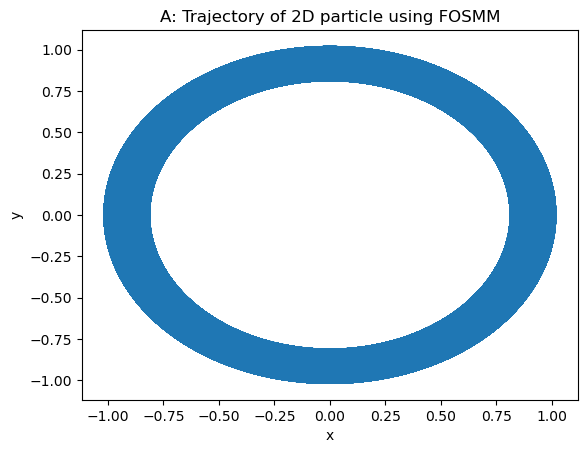

In [303]:
plt.title("A: Trajectory of 2D particle using FOSMM")
plt.plot(x1[0,:], x1[1,:])
plt.xlabel("x")
plt.ylabel("y")
plt.show()

Task A on model 3.2 with Fourth-order symmetric multistep method:

In [304]:
#Tokamak
#The static magentic field
def B2(x):
    Bx = -(2*x[1]+ x[0]*x[2])/(2*(x[0]**2 + x[1]**2))
    By = (2*x[0]- x[1]*x[2])/(2*(x[0]**2 + x[1]**2))
    Bz = (np.sqrt(x[0]**2 + x[1]**2)-1)/(2*(np.sqrt(x[0]**2 + x[1]**2)))
    return np.array([Bx, By, Bz])

#The vector potential
def A2(x):
    Ax = 0
    Ay = 1/2 *(x[0] - np.log(np.sqrt(x[0]**2 + x[1]**2) + x[0]))
    Az = -1/2 * (x[2]*np.arctan2(x[1],x[0])+ np.log(x[0]**2 + x[1]**2))
    return np.array([Ax, Ay, Az])

#The electrostatic potential
def U2(x):
    return 0

#The gradient of the electrostatic potential
def U_grad2(x):
    return 0

#Initial values
x02 = np.array([1.2, 0.0, 0.0])
v02 = np.array([0, 4.816*1e-4, -2.059*1e-3])
y02 = np.array([x02, v02])

x2, v2 , _= FOSMM(alpha, h, A2, U_grad2, B2, beta, T_max, y02)

0.000999999000001%
0.001999998000002%
0.002999997000003%
0.003999996000004%
0.0049999950000050005%
0.005999994000006%
0.006999993000007%
0.007999992000008%
0.008999991000009%
0.009999990000010001%
0.010999989000011%
0.011999988000012%
0.012999987000013%
0.013999986000014%
0.014999985000014999%
0.015999984000016%
0.016999983000017%
0.017999982000018%
0.018999981000018998%
0.019999980000020002%
0.020999979000021%
0.021999978000022%
0.022999977000023%
0.023999976000024%
0.024999975000024998%
0.025999974000026%
0.026999973000027003%
0.027999972000028%
0.028999971000029%
0.029999970000029998%
0.030999969000031%
0.031999968000032%
0.032999967000033%
0.033999966000034%
0.034999965000035%
0.035999964000036%
0.036999963000037%
0.037999962000037996%
0.038999961000039%
0.039999960000040004%
0.040999959000041%
0.041999958000042%
0.042999957000043%
0.043999956000044%
0.044999955000045%
0.045999954000046%
0.046999953000047%
0.047999952000048%
0.048999951000049%
0.049999950000049996%
0.05099994900005

Plotting for model 3.2:

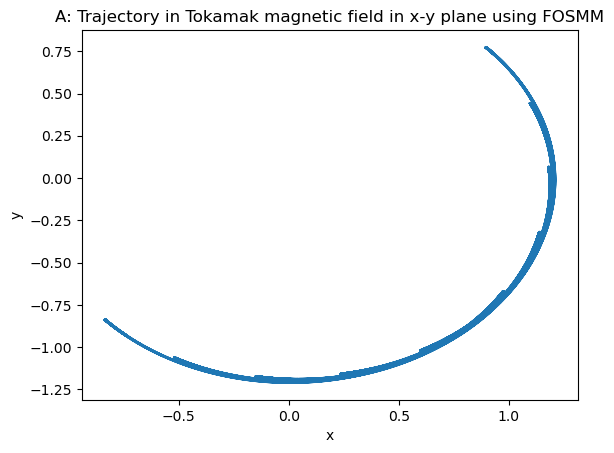

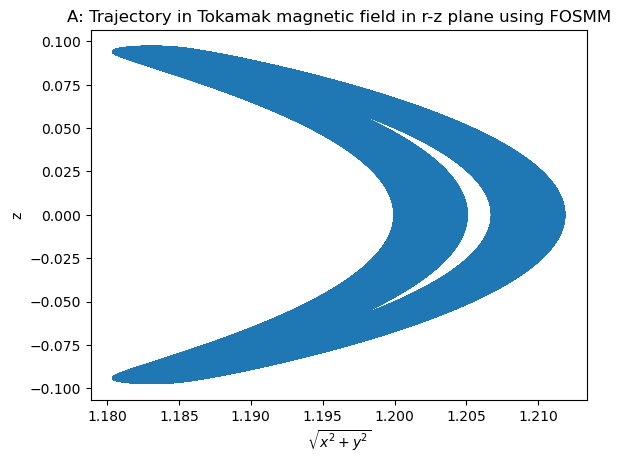

In [305]:
plt.title("A: Trajectory in Tokamak magnetic field in x-y plane using FOSMM")
plt.plot(x2[0,:], x2[1,:])
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.title("A: Trajectory in Tokamak magnetic field in r-z plane using FOSMM")
plt.plot(np.sqrt(x2[0,:]**2 + x2[1,:]**2), x2[2,:])
plt.xlabel(r"$\sqrt{x^2 + y^2}$")
plt.ylabel("z")
plt.show()

Compute referance 

In [306]:
t_span = (0, T_max)
N = int(T_max/h) + 1 
t_eval = np.linspace(0, T_max, N)

sol_2D = solve_ivp(ODE1, t_span, np.concatenate(y01),
    args=(B1, U_grad1),
    method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

sol_toka = solve_ivp(ODE1, t_span, np.concatenate(y02),
    args=(B2, U_grad2),
    method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)


Computing and plotting error:

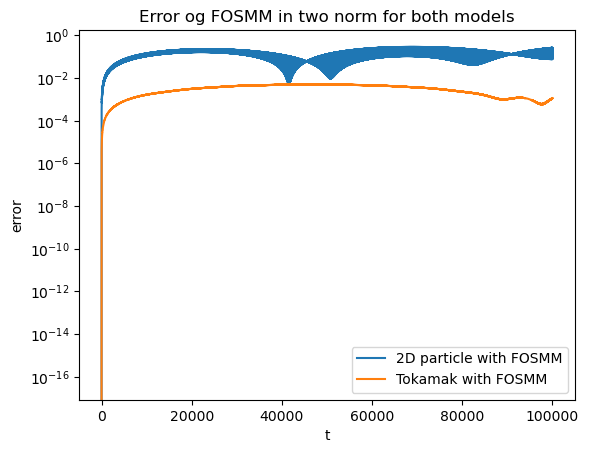

In [307]:
def error(x, xref):
    return np.linalg.norm(x-xref, ord=2, axis = 0)

error1_FOSMM = error(x1, sol_2D.y[:3])
error2_FOSMM = error(x2, sol_toka.y[:3])

plt.title("Error og FOSMM in two norm for both models")
plt.semilogy(t_eval,error1_FOSMM, label = "2D particle with FOSMM")
plt.semilogy(t_eval, error2_FOSMM, label = "Tokamak with FOSMM")
plt.ylabel("error")
plt.xlabel("t")
plt.legend()
plt.show()


Calculating energy conservation:

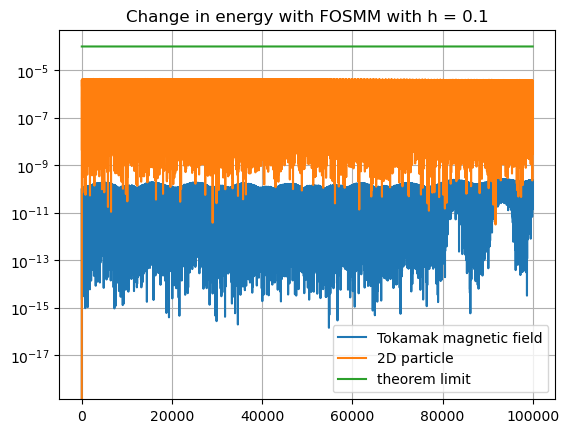

In [308]:
def energy(x, v, U):
    return 0.5*(np.linalg.norm(v, ord=2, axis = 0))**2 + U(x)

def energy_change(x, v, U):
    return np.abs(energy(x, v, U) - energy(x[:,0], v[:,0], U))

plt.title("Change in energy with FOSMM with h = 0.1")
plt.semilogy(t_eval, energy_change(x2, v2, U2), label="Tokamak magnetic field")
plt.semilogy(t_eval,energy_change(x1, v1, U1), label="2D particle")
plt.grid()
plt.plot(t_eval, h**(4)*np.ones(len(t_eval)), label="theorem limit")
plt.legend()
plt.show()


compare to theorem: h^-7 = 10^7 so should hold for the entire time interval, which it does, as we can see both errors are below the O(h^4) limit.

compare results 

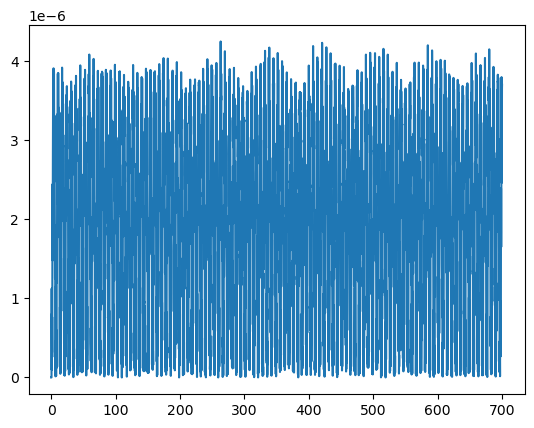

In [309]:
plt.plot(t_eval[:700*10], energy_change(x1[:,:700*10], v1[:,:700*10], U1))

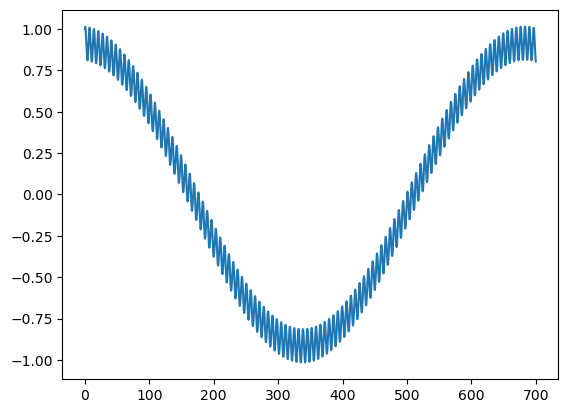

In [310]:
plt.plot(t_eval[:700*10], x1[1,:700*10])

SAMMENLIKN ALLE RESULTATER MED FORVENTNINGER! se oppgaveteksten


Task B) FOSMM

In [ ]:
T = 1e4
h = 0.1
#2D particle (1) and Tokamak field (2)
e1 = []
e2 = []
t1 = []
t2 = []
h_arr = []
for i in range(3):
    hi = h/2**i
    h_arr.append(hi)
    N = int(T/hi) + 1 
    t_span = (0,T)
    t_eval = np.linspace(0,T, N)
    xi1, _ , ti1 = FOSMM(alpha, hi, A1, U_grad1, B1, beta, T, y01)
    xi2, _ , ti2 = FOSMM(alpha, hi, A2, U_grad2, B2, beta, T, y02)

    xi1_ref_sol = solve_ivp(ODE1, t_span, np.concatenate(y01), args=(B1, U_grad1), method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)
    xi2_ref_sol = solve_ivp(ODE1, t_span, np.concatenate(y02), args=(B2, U_grad2),method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

    xi1_ref = xi1_ref_sol.y[:3]
    xi2_ref = xi2_ref_sol.y[:3]

    t1.append(ti1)
    t2.append(ti2)

    e1.append(np.linalg.norm(xi1[:,-1] - xi1_ref[:,-1], ord=2, axis=0))
    e2.append(np.linalg.norm(xi2[:,-1] - xi2_ref[:,-1], ord=2, axis=0))
h_arr = np.array(h_arr)

0.009999900000999989%
0.019999800001999978%
0.02999970000299997%
0.039999600003999956%
0.049999500004999954%
0.05999940000599994%
0.06999930000699993%
0.07999920000799991%
0.08999910000899991%
0.09999900000999991%
0.10999890001099988%
0.11999880001199988%
0.12999870001299987%
0.13999860001399986%
0.14999850001499984%
0.15999840001599983%
0.16999830001699984%
0.17999820001799982%
0.1899981000189998%
0.19999800001999982%
0.2099979000209998%
0.21999780002199976%
0.22999770002299977%
0.23999760002399975%
0.24999750002499976%
0.25999740002599975%
0.26999730002699973%
0.2799972000279997%
0.2899971000289997%
0.2999970000299997%
0.3099969000309997%
0.31999680003199965%
0.3299967000329997%
0.3399966000339997%
0.34999650003499966%
0.35999640003599964%
0.3699963000369996%
0.3799962000379996%
0.3899961000389996%
0.39999600003999963%
0.4099959000409996%
0.4199958000419996%
0.42999570004299953%
0.4399956000439995%
0.4499955000449996%
0.45999540004599954%
0.4699953000469995%
0.4799952000479995%
0.489

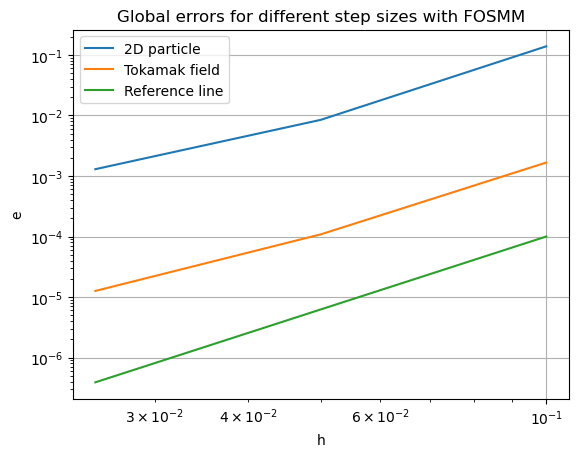

In [ ]:
#CONST = 10**3

plt.title("Global errors for different step sizes with FOSMM")
plt.xlabel("h")
plt.ylabel("e")
plt.loglog(h_arr, e1, label = "2D particle")
plt.loglog(h_arr, e2, label = "Tokamak field")
plt.loglog(h_arr, h_arr**4, label = "Reference line")
#plt.vlines(CONST/h_arr, ymax= 1, ymin=0)
plt.grid()
plt.legend()
plt.show()


as we can see, the errors grow asymptotically as h**4

VISE MER ORDENTLIG???

fra øving 2: Compute Rn,0 for n= 0,1,2 (composite trapezoidal rule with 1, 2, and 4
subintervals). Verify that the errors are approximately in the ratio 4 : 1
when the step size is halved, consistent with O(h2) convergence.
DETTE MÅ FORKLARES
OI NEI MEN i følge argumentasjonen for RK4 så er jo da denne ikke orden 4??? For h < h0 vil de være større enn O(h^4)?

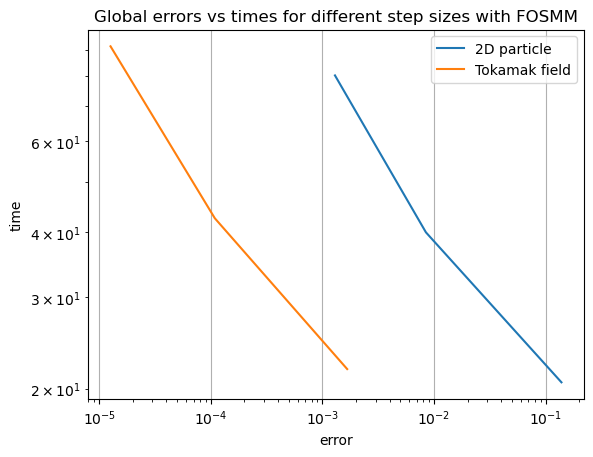

In [ ]:
plt.title("Global errors vs times for different step sizes with FOSMM")
plt.ylabel("time")
plt.xlabel("error")
plt.loglog(e1, t1, label = "2D particle")
plt.loglog(e2, t2, label = "Tokamak field")
#plt.vlines(CONST/h_arr, ymax= 1, ymin=0)
plt.grid()
plt.legend()
plt.show()


which method most efficient for a given tolerrance?

makes sense, more time = more accurcay and vice versa

slett etterpå

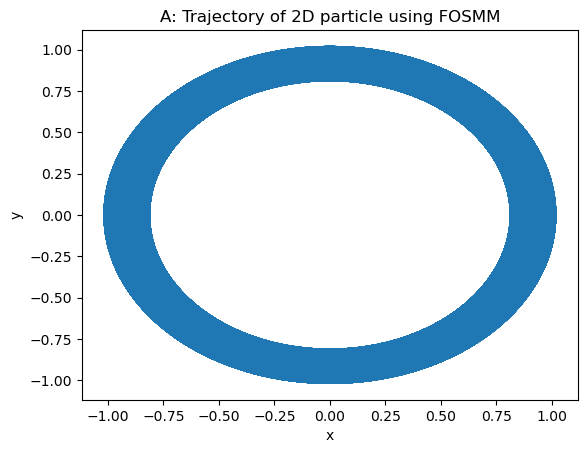

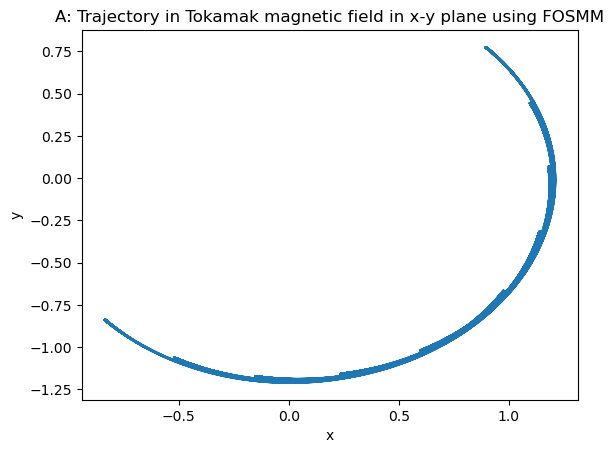

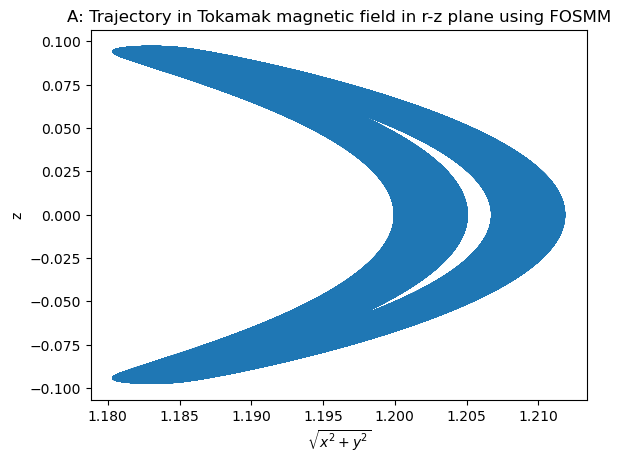

In [ ]:
#runge kutte for å verifisere
def f_rk(x, v, B, U_grad):
    return np.cross(v, B(x)) - U_grad(x)

def RK4_step(h, f, xn, vn, B, U_grad):
    k1v = h*f(xn, vn, B, U_grad)
    k1x = h*vn
    k2v = h*f(xn + 1/2*k1x, vn + 1/2*k1v, B, U_grad)
    k2x = h*(vn + 1/2*k1v)
    k3v = h*f(xn + 1/2*k2x, vn + 1/2*k2v, B, U_grad)
    k3x = h*(vn + 1/2*k2v)
    k4v = h*f(xn + k3x, vn + k3v, B, U_grad)
    k4x = h*(vn + k3v)
    vnp1 = vn + 1/6*(k1v + 2*k2v + 2*k3v + k4v)
    xnp1 = xn + 1/6*(k1x + 2*k2x + 2*k3x + k4x)
    return xnp1, vnp1 #time t_curr + h


def RK4(x0, v0, f, B, U_grad, T_max, h):
    N = int(T_max/h) + 1 #number of steps
    x = np.zeros((3, N))
    v = np.zeros((3, N))
    x[:, 0] = x0   
    v[:, 0] = v0
    x_curr = x0
    v_curr = v0
    start = perf_counter()
    for i in range(1,N):
        x_next, v_next = RK4_step(h, f, x_curr, v_curr, B, U_grad)
        x_curr = x_next
        v_curr = v_next
        x[:,i] = x_curr
        v[:,i] = v_curr
    stop = perf_counter()
    return x, v, stop-start


h = 0.1
T_max = 1e5

x1RK, v1RK, _ = RK4(x01, v01, f_rk, B1, U_grad1, T_max, h)

x2RK, v2RK, _ = RK4(x02, v02, f_rk, B2, U_grad2, T_max, h)



plt.title("A: Trajectory of 2D particle using FOSMM")
plt.plot(x1RK[0,:], x1RK[1,:])
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.title("A: Trajectory in Tokamak magnetic field in x-y plane using FOSMM")
plt.plot(x2RK[0,:], x2RK[1,:])
plt.xlabel("x")
plt.ylabel("y")
plt.show()

plt.title("A: Trajectory in Tokamak magnetic field in r-z plane using FOSMM")
plt.plot(np.sqrt(x2RK[0,:]**2 + x2RK[1,:]**2), x2RK[2,:])
plt.xlabel(r"$\sqrt{x^2 + y^2}$")
plt.ylabel("z")
plt.show()


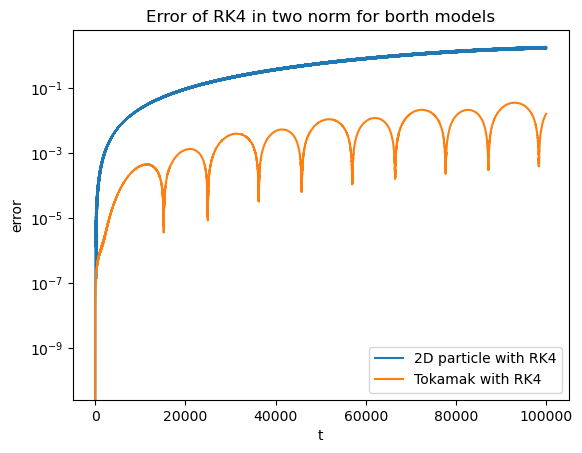

In [ ]:
error1_RK = error(x1RK, sol_2D.y[:3])
error2_RK = error(x2RK, sol_toka.y[:3])
N_RK = int(T_max/h) + 1 
t_eval_RK = np.linspace(0, T_max, N_RK)

plt.title("Error of RK4 in two norm for borth models")
plt.semilogy(t_eval_RK,error1_RK, label = "2D particle with RK4")
plt.semilogy(t_eval_RK, error2_RK, label = "Tokamak with RK4")
plt.ylabel("error")
plt.xlabel("t")
plt.legend()
plt.show()

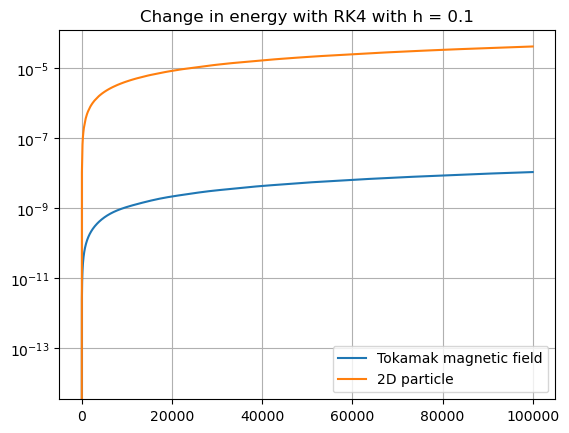

In [ ]:
plt.title("Change in energy with RK4 with h = 0.1")
plt.semilogy(t_eval_RK, energy_change(x2RK, v2RK, U2), label="Tokamak magnetic field")
plt.semilogy(t_eval_RK,energy_change(x1RK, v1RK, U1), label="2D particle")
plt.grid()
plt.legend()
plt.show()

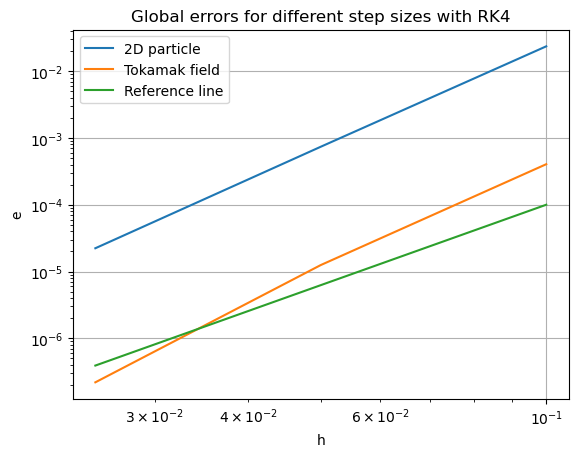

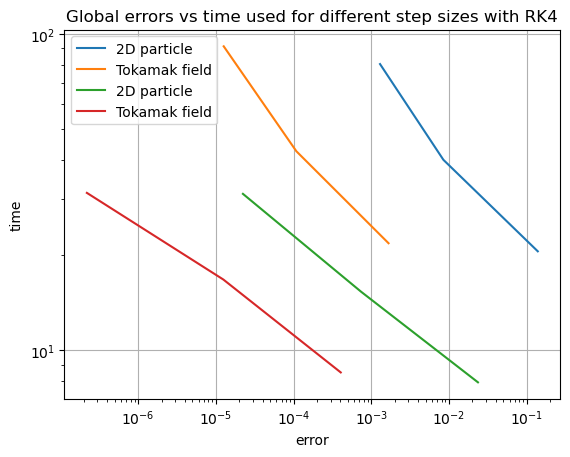

In [ ]:
TRK = 1e4
#2D particle (1) and Tokamak field (2)
e1RK = []
e2RK = []
t1RK = []
t2RK = []
h_arrRK = []
for i in range(3):
    hi = h/2**i
    h_arrRK.append(hi)
    N = int(TRK/hi) + 1 
    t_span = (0,TRK)
    t_eval = np.linspace(0,TRK, N)
    xi1, _ , ti1= RK4(x01, v01, f_rk, B1, U_grad1, TRK, hi)
    xi2, _ , ti2= RK4(x02, v02, f_rk, B2, U_grad2, TRK, hi)

    xi1_ref_sol = solve_ivp(ODE1, t_span, np.concatenate(y01), args=(B1, U_grad1), method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)
    xi2_ref_sol = solve_ivp(ODE1, t_span, np.concatenate(y02), args=(B2, U_grad2),method="DOP853", rtol=1e-12, atol=1e-14, t_eval=t_eval)

    xi1_ref = xi1_ref_sol.y[:3]
    xi2_ref = xi2_ref_sol.y[:3]

    t1RK.append(ti1)
    t2RK.append(ti2)  

    e1RK.append(np.linalg.norm(xi1[:,-1] - xi1_ref[:,-1], ord=2, axis=0))
    e2RK.append(np.linalg.norm(xi2[:,-1] - xi2_ref[:,-1], ord=2, axis=0))
h_arrRK = np.array(h_arrRK)


plt.title("Global errors for different step sizes with RK4")
plt.xlabel("h")
plt.ylabel("e")
plt.loglog(h_arrRK, e1RK, label = "2D particle")
plt.loglog(h_arrRK, e2RK, label = "Tokamak field")
plt.loglog(h_arrRK, h_arrRK**4, label = "Reference line")
plt.grid()
plt.legend()
plt.show()

plt.title("Global errors vs time used for different step sizes with RK4")
plt.ylabel("time")
plt.xlabel("error")
plt.loglog(e1, t1, label = "2D particle")
plt.loglog(e2, t2, label = "Tokamak field")
plt.loglog(e1RK,t1RK, label = "2D particle")
plt.loglog(e2RK,t2RK, label = "Tokamak field")
plt.grid()
plt.legend()
plt.show()



since the plots of the error have a steeper slope than the h**4 plot, for some h0 >0 we will have that the errors are below Ch^4 for all h <= h0, thus the O(h^4) condition for convergence of order p is satisfied. 